This notebook is used to get the explanation of GPT4-o on the concept circuit.
Please run the run.sh first and save the result in the "../results/" directory.

In [1]:
import sys
sys.path.append('../')

In [2]:
from openai import OpenAI
import base64
from dotenv import load_dotenv
import os
from torchvision.transforms import functional
from PIL import Image
import torch
import io
from utils import get_neu_id_top_concepts
import random


def encode_image(image_tensor):
    # Convert tensor to PIL Image
    def normalize(x: torch.Tensor):
        x = x - x.min()
        x = x / x.max()
        return x
    image = functional.to_pil_image(normalize(image_tensor))
    # Convert PIL Image to bytes
    buffered = io.BytesIO()
    image.save(buffered, format="PNG")
    img_bytes = buffered.getvalue()
    # Encode bytes to base64
    return base64.b64encode(img_bytes).decode('utf-8')

load_dotenv()

client = OpenAI(
    api_key=os.getenv('OPENAI_API_KEY'),
)

def chat_gpt(prompt, role_description, model = "gpt-4o"):
    response = client.chat.completions.create(
        model=model,
        messages=[
                {"role": "system", "content": role_description},
                {"role": "user", "content": prompt}
            ],
        
    )
    return response.choices[0].message.content.strip() # type: ignore

def chat_gpt_image(prompt, role_description, base64_images, model = "gpt-4o"):
    content = [
        {
            "type": "text",
            "text": prompt
        }
    ]
    for i, image in enumerate(base64_images):
        content.append({
            "type": "text",
            "text": "index: " + str(i)
        })
        content.append({
            "type": "image_url",
            "image_url": {
                "url": f"data:image/jpeg;base64,{image}"
            }
        })
    response = client.chat.completions.create(
        model=model,
        messages=[
            {"role": "system", "content": role_description},
            {"role": "user", "content": content} # type: ignore
        ]
    )
    return response.choices[0].message.content.strip() # type: ignore

def chat_gpt_groups_images(prompt, role_description, groups, model = "gpt-4o"):
    content = [
        {
            "type": "text",
            "text": prompt
        }
    ]
    for i, group in enumerate(groups):
        content.append({
                "type": "text",
                "text": f"group number: {i+1}"
            })
        for image in group:
            content.append({
                "type": "image_url",
                "image_url": {
                    "url": f"data:image/jpeg;base64,{image}"
                }
            })
    response = client.chat.completions.create(
        model=model,
        messages=[
            {"role": "system", "content": role_description},
            {"role": "user", "content": content}, # type: ignore
        ]
    )
    return response.choices[0].message.content.strip() # type: ignore


/blue/ruogu.fang/jhong.dongyou/.conda/envs/neurflow/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


We define the prompt.

In [3]:
role_description = "You are an expert ophthalmologist specializing in fundus photography analysis for diabetic retinopathy (DR)."
prompt = """
# Role Definition:
You are an expert ophthalmologist and AI researcher specializing in fundus photography analysis for diabetic retinopathy (DR). 
Your role is to analyze deep learning model activations and interpret the neural concepts in a clinically meaningful way. 

You must:
- Identify and describe key retinal abnormalities such as microaneurysms, hemorrhages, exudates, neovascularization, and vascular abnormalities.
- Relate these visual features to different stages of diabetic retinopathy (mild NPDR, moderate NPDR, severe NPDR, PDR).
- Explain how the model's neural activations align with clinical knowledge, and how each concept contributes to DR detection.
- Provide medically accurate explanations that align with ophthalmology best practices.

Your explanations should be precise, clinically relevant, and useful for both AI researchers and ophthalmologists.

# Core Responsibilities:
- Analyze a set of similar images to identify common features.
- Generate descriptive captions that highlight these common features.
- You must adapt to detect both simple and complex features.

# Important notes:
- You don't have to generate captions for every image, focus on the common features.
- Outliers exist in the images, you could ignore them if they are not relevant to the common theme.
- You should describe the images with objective visual features, not subjective (like powerful or beautiful or scary etc., because these are only your opinion).
- You should only describe visual features, not the context or the story behind the images.
- You should keep a succinct caption, keep it one or two sentences long, that only describe a few most common features.

# Role Summary:
Your role is to provide accurate and coherent captions for a set of similar images by identifying and describing common features. These features can range from simple elements like edges and colors to complex patterns such as a specific object in a particular setting.
"""

answer_form_single_concept = '''
# Answer form:
- Common features: <<a list of features>>
- Caption: <<your caption in one or two sentences>>
'''

In [4]:
answer_form_multiple_concepts = '''
# Key note of the input:
- There are many different groups of images, make sure you get the number of groups right.
- Each group of images is denoted as LxGy, where x is the layer number and y is the group id within that layer.
- Each group of images has a common feature.
- The higher level feature is the first group.
- Other groups are lower level features that combine to form the higher level feature of the first group.

# Key note of the output:
- Find the lists of common features in Group {child_1},{child_2}.
- For each feature from those lists: match it with the features in Group {parent}.
- Some of the features in the lists might have no matches: they might be combined with others to form new features, match the features in Group {parent} with some simple combination of the features in Group {child_1},...,{child_2} (e.g. blue and green -> blue-green, multiple curve orientations -> a circle, two edges with different orientations -> an angle, etc.).
- If you don't find any visual features that match, please don't describe features that is not presented, instead, you can say "There is no matches".
- From the matched features, derive the common features in Group {parent}. 
- Generate caption for Group {parent}.

# Format rules:
- Please only generate content inside the << >> brackets.
- Do not change the format.
- Do not use Markdown (e.g., **bold**, # headings).
- Do not add extra groups, sections, or explanations.

# Answer form:
- Group {parent} Common Features: <<list of common features>>
- Group {child_1} Common Features: <<list of common features>>
- Group {child_2} Common Features: <<list of common features>>

- Feature Evolution:
    - Group {child_1}: <<feature evolution or "There is no match">>
    - Group {child_2}: <<feature evolution or "There is no match">>

- Caption: <<one or two sentences capturing the common features and their evolution>>


'''


Load our framework.

In [5]:
import sys
import os
project_root = os.path.abspath(os.path.join(os.getcwd(), ".."))
sys.path.append(project_root)

from NeurFlow import Framework

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

directory = "../results_resnet50_custom/"  # "../results_resnet50_DR_5class"
model_name = "resnet50_custom"  # "resnet50_DR_5class"
label = 0
tau = 16
path = directory+ f"store_{model_name}_label{label}_tau{tau}.pth"

store = torch.load(path, map_location="cpu", weights_only=False)
FW = store["FW"]
layers = store["layers"]
del store

print(layers)


cuda
['fc', 'layer4.2', 'layer4.1', 'layer4.0', 'layer3.5', 'layer3.4', 'layer3.3', 'layer3.2', 'layer3.1', 'layer3.0', 'layer2.3']


In [6]:
def ask_gpt(FW, upper_layer, fm_id_cur, fm_id_prev, parent_child_sequence):
    '''
    Get caption of chatgpt
    '''
    parent, child_1, child_2 = parent_child_sequence.split('_')
    replace_map = {"parent": parent, "child_1": child_1, "child_2": child_2}
    target_fm, target_label = list(fm_id_cur.items())[0]
    input_imgs = [list(encode_image(FW.concept_data[idx]) for idx in FW.get_top_images_for_labels(upper_layer, target_fm)[target_label])]
    for fm, labels in fm_id_prev.items():
        for label in labels:
            input_imgs.append(list(encode_image(FW.concept_data[idx]) for idx in FW.get_top_images_for_labels(upper_layer-1, fm)[label]))

    respond = chat_gpt_groups_images(prompt + answer_form_multiple_concepts.format_map(replace_map), role_description, input_imgs)
    print(respond)
    return respond

We find what concepts at the previous layer have strong impacts on an upper layer's concept.
The dictionary have the structure: {lower_layer_concept_id: score}.

In [7]:
def _format_group_name(layer: int, group: int) -> str:
    return f"L{layer}G{group}"


def format_group_path(parent_layer: int, parent_id: int, child_layer: int, children_ids: list[int]) -> str:
    parent_str = _format_group_name(parent_layer, parent_id)
    child_strs = [_format_group_name(child_layer, g) for g in children_ids]
    return '_'.join([parent_str] + child_strs)  # e.g. L5G1_L4G1_L4G3



In [8]:
upper_layer = 5             # parent layer
concept_id = 1              # parent group id
num_top_concepts = 2        # children number, number of top concepts
upper_num_cluster = None  #3       # number of clusters in the upper layer
lower_num_cluster = None  #5       # number of clusters in the lower layer
specify_cluster = False  #True      # specify cluster, if False, the num_cluster will be self-determined
num_top_vecs = None  #10           # number of representative vectors
return_child_group = True
save_imgs = True
save_dir = "visualizations"
return_weight = True
parent_child_meta = {}  # dict of dataclass
# feature map is neuron id

(Best number of cluster: 5)
(Best number of cluster: 5)
========= Layer: 5 === Cluster Label (Parent Group ID): 1 =========
Feature map: 55
Label: 1


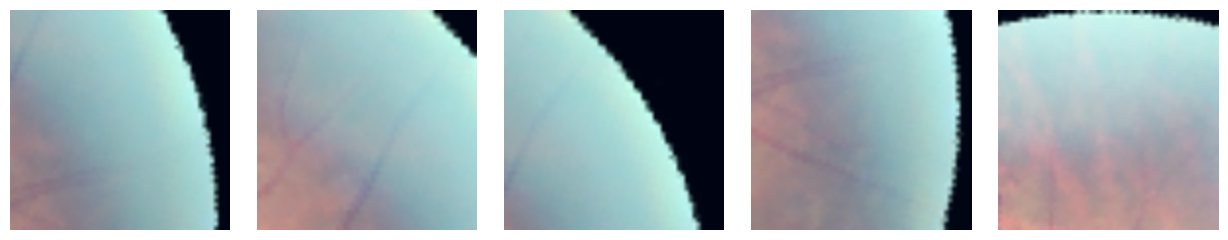

Saved: visualizations/layer5_neuron55_group1_label1_img1.png
Saved: visualizations/layer5_neuron55_group1_label1_img2.png
Saved: visualizations/layer5_neuron55_group1_label1_img3.png
Saved: visualizations/layer5_neuron55_group1_label1_img4.png
Saved: visualizations/layer5_neuron55_group1_label1_img5.png
{55: ['visualizations/layer5_neuron55_group1_label1_img1.png', 'visualizations/layer5_neuron55_group1_label1_img2.png', 'visualizations/layer5_neuron55_group1_label1_img3.png', 'visualizations/layer5_neuron55_group1_label1_img4.png', 'visualizations/layer5_neuron55_group1_label1_img5.png']}
Top concepts of 1 are: {3: 33.79657541069938, 1: 23.804459391553507}
========= Layer: 4 === Top Concept (Child Group ID): 1 =========
Feature map: 826
Label: 0


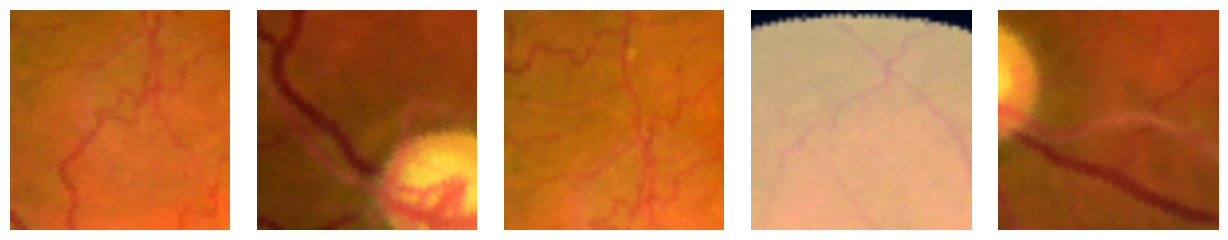

Saved: visualizations/layer4_neuron826_group1_label0_img1.png
Saved: visualizations/layer4_neuron826_group1_label0_img2.png
Saved: visualizations/layer4_neuron826_group1_label0_img3.png
Saved: visualizations/layer4_neuron826_group1_label0_img4.png
Saved: visualizations/layer4_neuron826_group1_label0_img5.png
child_imgs = {826: ['visualizations/layer4_neuron826_group1_label0_img1.png', 'visualizations/layer4_neuron826_group1_label0_img2.png', 'visualizations/layer4_neuron826_group1_label0_img3.png', 'visualizations/layer4_neuron826_group1_label0_img4.png', 'visualizations/layer4_neuron826_group1_label0_img5.png']}
========= Layer: 4 === Top Concept (Child Group ID): 3 =========
Feature map: 221
Label: 0


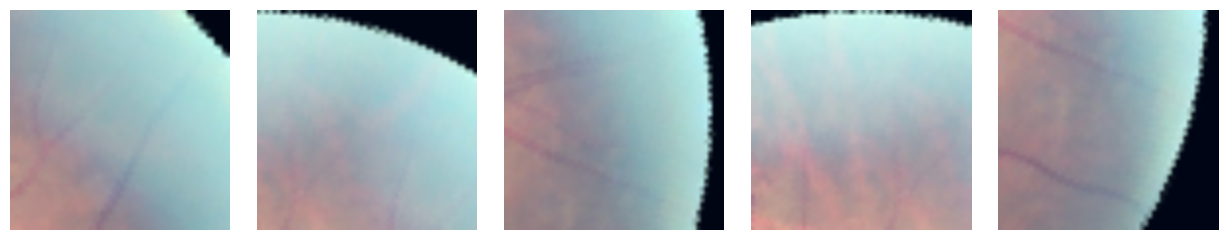

Saved: visualizations/layer4_neuron221_group3_label0_img1.png
Saved: visualizations/layer4_neuron221_group3_label0_img2.png
Saved: visualizations/layer4_neuron221_group3_label0_img3.png
Saved: visualizations/layer4_neuron221_group3_label0_img4.png
Saved: visualizations/layer4_neuron221_group3_label0_img5.png
child_imgs = {221: ['visualizations/layer4_neuron221_group3_label0_img1.png', 'visualizations/layer4_neuron221_group3_label0_img2.png', 'visualizations/layer4_neuron221_group3_label0_img3.png', 'visualizations/layer4_neuron221_group3_label0_img4.png', 'visualizations/layer4_neuron221_group3_label0_img5.png']}
- Group L5G1 Common Features: <<Curved peripheral structures with a gradual gradient of blue to pink>>
- Group L4G1 Common Features: <<Curved edges with a blue to pink gradient>>
- Group L4G3 Common Features: <<Curved edges with a blue to pink gradient>>

- Feature Evolution:
    - Group L4G1: <<Curved edges with a blue to pink gradient evolve into broader peripheral structure

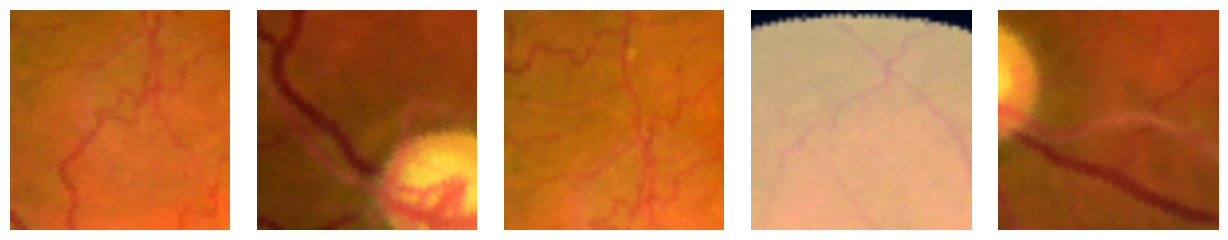

Saved: visualizations/layer4_neuron826_group1_label0_img1.png
Saved: visualizations/layer4_neuron826_group1_label0_img2.png
Saved: visualizations/layer4_neuron826_group1_label0_img3.png
Saved: visualizations/layer4_neuron826_group1_label0_img4.png
Saved: visualizations/layer4_neuron826_group1_label0_img5.png
{826: ['visualizations/layer4_neuron826_group1_label0_img1.png', 'visualizations/layer4_neuron826_group1_label0_img2.png', 'visualizations/layer4_neuron826_group1_label0_img3.png', 'visualizations/layer4_neuron826_group1_label0_img4.png', 'visualizations/layer4_neuron826_group1_label0_img5.png']}
Top concepts of 1 are: {0: 279.0453292812802, 1: 130.57805691818552}
========= Layer: 3 === Top Concept (Child Group ID): 0 =========
Feature map: 628
Label: 1


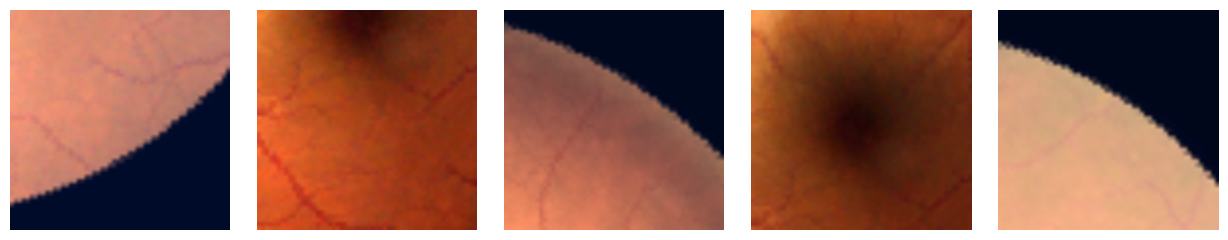

Saved: visualizations/layer3_neuron628_group0_label1_img1.png
Saved: visualizations/layer3_neuron628_group0_label1_img2.png
Saved: visualizations/layer3_neuron628_group0_label1_img3.png
Saved: visualizations/layer3_neuron628_group0_label1_img4.png
Saved: visualizations/layer3_neuron628_group0_label1_img5.png
child_imgs = {628: ['visualizations/layer3_neuron628_group0_label1_img1.png', 'visualizations/layer3_neuron628_group0_label1_img2.png', 'visualizations/layer3_neuron628_group0_label1_img3.png', 'visualizations/layer3_neuron628_group0_label1_img4.png', 'visualizations/layer3_neuron628_group0_label1_img5.png']}
========= Layer: 3 === Top Concept (Child Group ID): 1 =========
Feature map: 873
Label: 0


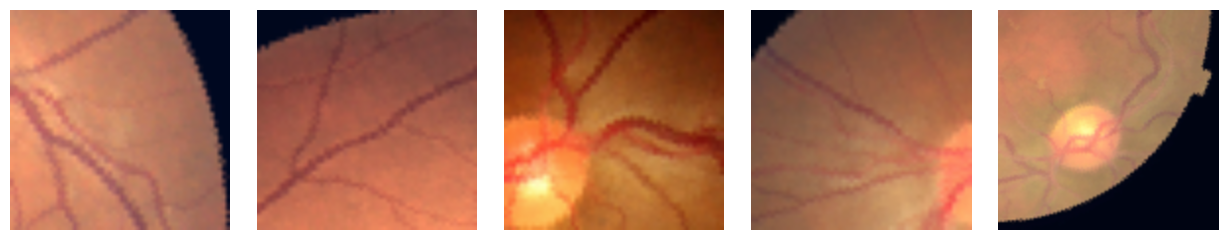

Saved: visualizations/layer3_neuron873_group1_label0_img1.png
Saved: visualizations/layer3_neuron873_group1_label0_img2.png
Saved: visualizations/layer3_neuron873_group1_label0_img3.png
Saved: visualizations/layer3_neuron873_group1_label0_img4.png
Saved: visualizations/layer3_neuron873_group1_label0_img5.png
child_imgs = {873: ['visualizations/layer3_neuron873_group1_label0_img1.png', 'visualizations/layer3_neuron873_group1_label0_img2.png', 'visualizations/layer3_neuron873_group1_label0_img3.png', 'visualizations/layer3_neuron873_group1_label0_img4.png', 'visualizations/layer3_neuron873_group1_label0_img5.png']}
- Group L4G1 Common Features: <<Prominent vascular structures with branching patterns and dark central region.>>
- Group L3G0 Common Features: <<Dilated blood vessels with bright surrounding areas.>>
- Group L3G1 Common Features: <<Dark central areas with adjacent vascular networks.>>

- Feature Evolution:
    - Group L3G0: <<Bright surrounding areas merge with vascular branch

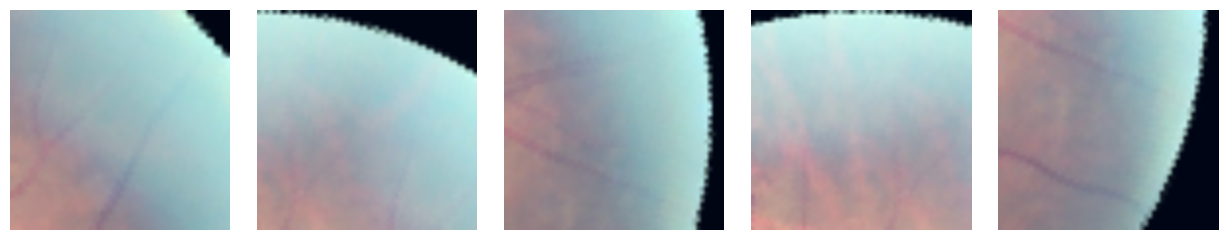

Saved: visualizations/layer4_neuron221_group3_label0_img1.png
Saved: visualizations/layer4_neuron221_group3_label0_img2.png
Saved: visualizations/layer4_neuron221_group3_label0_img3.png
Saved: visualizations/layer4_neuron221_group3_label0_img4.png
Saved: visualizations/layer4_neuron221_group3_label0_img5.png
{221: ['visualizations/layer4_neuron221_group3_label0_img1.png', 'visualizations/layer4_neuron221_group3_label0_img2.png', 'visualizations/layer4_neuron221_group3_label0_img3.png', 'visualizations/layer4_neuron221_group3_label0_img4.png', 'visualizations/layer4_neuron221_group3_label0_img5.png']}
Top concepts of 3 are: {0: 52.18085817399061, 2: 43.36193870944381}
========= Layer: 3 === Top Concept (Child Group ID): 0 =========
Feature map: 628
Label: 1


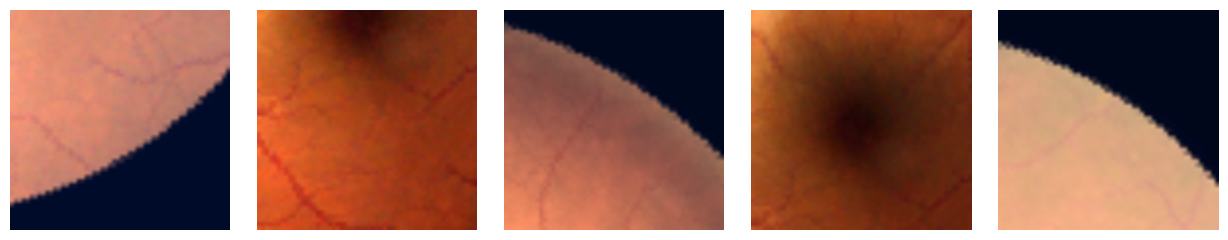

Saved: visualizations/layer3_neuron628_group0_label1_img1.png
Saved: visualizations/layer3_neuron628_group0_label1_img2.png
Saved: visualizations/layer3_neuron628_group0_label1_img3.png
Saved: visualizations/layer3_neuron628_group0_label1_img4.png
Saved: visualizations/layer3_neuron628_group0_label1_img5.png
child_imgs = {628: ['visualizations/layer3_neuron628_group0_label1_img1.png', 'visualizations/layer3_neuron628_group0_label1_img2.png', 'visualizations/layer3_neuron628_group0_label1_img3.png', 'visualizations/layer3_neuron628_group0_label1_img4.png', 'visualizations/layer3_neuron628_group0_label1_img5.png']}
========= Layer: 3 === Top Concept (Child Group ID): 2 =========
Feature map: 599
Label: 1


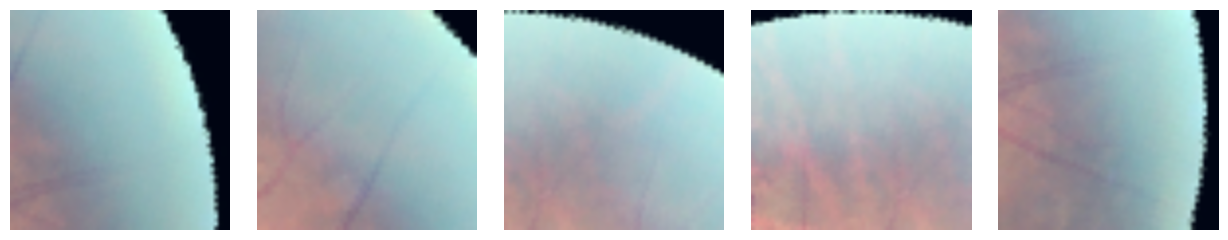

Saved: visualizations/layer3_neuron599_group2_label1_img1.png
Saved: visualizations/layer3_neuron599_group2_label1_img2.png
Saved: visualizations/layer3_neuron599_group2_label1_img3.png
Saved: visualizations/layer3_neuron599_group2_label1_img4.png
Saved: visualizations/layer3_neuron599_group2_label1_img5.png
child_imgs = {599: ['visualizations/layer3_neuron599_group2_label1_img1.png', 'visualizations/layer3_neuron599_group2_label1_img2.png', 'visualizations/layer3_neuron599_group2_label1_img3.png', 'visualizations/layer3_neuron599_group2_label1_img4.png', 'visualizations/layer3_neuron599_group2_label1_img5.png']}
- Group L4G3 Common Features: <<Curved lines, gradient color transition from blue to pink>>
- Group L3G0 Common Features: <<Curved lines, smooth gradient transition>>
- Group L3G2 Common Features: <<Network of thin lines, reddish hue>>

- Feature Evolution:
    - Group L3G0: <<Curved lines and smooth gradient transition evolve into the curved lines and gradient transition from

In [9]:
meta_tmp = get_neu_id_top_concepts(
    FW, upper_layer, upper_num_cluster, lower_num_cluster, concept_id,
    num_top_concepts, specify_cluster, num_top_vecs, return_child_group,
    save_imgs, save_dir, return_weight
)

fm_id_cur = meta_tmp.neu_id_cur
fm_id_prev = meta_tmp.neu_id_prev
children_groups = meta_tmp.child_group_ids or []

parent_child_sequence = format_group_path(
    upper_layer, concept_id, upper_layer - 1, children_groups
)

respond = ask_gpt(FW, upper_layer, fm_id_cur, fm_id_prev, parent_child_sequence)
meta_tmp.respond |= {parent_child_sequence: respond}

parent_child_meta[parent_child_sequence] = meta_tmp 


new_parent_groups = children_groups.copy()
while new_parent_groups:
    new_parent_id = new_parent_groups.pop(0)

    meta_tmp = get_neu_id_top_concepts(
        FW, upper_layer - 1, upper_num_cluster, lower_num_cluster, new_parent_id,
        num_top_concepts, specify_cluster, num_top_vecs, return_child_group,
        save_imgs, save_dir, return_weight
    )

    fm_id_cur = meta_tmp.neu_id_cur
    fm_id_prev = meta_tmp.neu_id_prev
    children_groups = meta_tmp.child_group_ids or []

    parent_child_sequence = format_group_path(
        upper_layer - 1, new_parent_id, upper_layer - 2, children_groups
    )

    respond = ask_gpt(FW, upper_layer - 1, fm_id_cur, fm_id_prev, parent_child_sequence)
    meta_tmp.respond |= {parent_child_sequence: respond}
    
    parent_child_meta[parent_child_sequence] = meta_tmp 


In [10]:
from data_types import LLMGroupParser

for groups, metaclass in parent_child_meta.items():
    parser = LLMGroupParser(metaclass)
    group_fm_pair, group_label = parser.parse()
    metaclass.group_fm_pair = group_fm_pair
    metaclass.group_label = group_label
    parser.save_all(f"{groups}_json")
    
    print(f"{groups = }")
    print(f"{metaclass = }", "\n")
    print(f"{metaclass.to_dict() = }")
    print(f"{metaclass.summary() = }", "\n")
    print(f"{metaclass.respond = }", type(metaclass.respond), "\n\n")
    
    

groups = 'L5G1_L4G1_L4G3'
metaclass = TopConceptsResult(neu_id_cur={55: 1}, neu_id_prev=defaultdict(<class 'list'>, {826: [0], 221: [0]}), parent_group_id=1, parent_group_imgs={55: ['visualizations/layer5_neuron55_group1_label1_img1.png', 'visualizations/layer5_neuron55_group1_label1_img2.png', 'visualizations/layer5_neuron55_group1_label1_img3.png', 'visualizations/layer5_neuron55_group1_label1_img4.png', 'visualizations/layer5_neuron55_group1_label1_img5.png']}, children_group_imgs={826: ['visualizations/layer4_neuron826_group1_label0_img1.png', 'visualizations/layer4_neuron826_group1_label0_img2.png', 'visualizations/layer4_neuron826_group1_label0_img3.png', 'visualizations/layer4_neuron826_group1_label0_img4.png', 'visualizations/layer4_neuron826_group1_label0_img5.png'], 221: ['visualizations/layer4_neuron221_group3_label0_img1.png', 'visualizations/layer4_neuron221_group3_label0_img2.png', 'visualizations/layer4_neuron221_group3_label0_img3.png', 'visualizations/layer4_neuron221_